# 📊 TickerMiner
Notebook de Analisis Exploratorio de Datos (EDA)

In [1]:
# Preliminares
import pandas as pd

from src.cat_modeling import cargar_datos_clean
from src.transform import categorizar_en_cuantiles, encontrar_columnas
from src.eda_utils import (
    mostrar_asimetrias, mostrar_missings, pintar_columna,
    top_correlaciones, pintar_violin_plots 
)

# Cargar fichero de precios
df_clean = cargar_datos_clean()

df_clean.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 966 entries, 2007-04-30 to 2026-10-26
Data columns (total 81 columns):
 #   Column                                        Non-Null Count  Dtype  
---  ------                                        --------------  -----  
 0   AUDUSD_Close_return                           966 non-null    float64
 1   EURUSD_Close_return                           966 non-null    float64
 2   GBPUSD_Close_return                           966 non-null    float64
 3   USDCAD_Close_return                           966 non-null    float64
 4   USDCHF_Close_return                           966 non-null    float64
 5   USDJPY_Close_return                           966 non-null    float64
 6   EURUSD_Close_return_lag1                      966 non-null    float64
 7   GBPUSD_Close_return_lag1                      966 non-null    float64
 8   USDJPY_Close_return_lag1                      966 non-null    float64
 9   USDCHF_Close_return_lag1                      

## Analisis de variables

In [2]:
# Missings
mostrar_missings(df_clean)

Oil_High_Low_spread_lag1_log    0.001035
dtype: float64

In [3]:
# Descripcion de variables
columnas_clean = df_clean.columns.tolist()
cadena = "Volume_pct_diff_sma20"
columnas = encontrar_columnas(columnas_target=columnas_clean, cadena=cadena)

df_clean[columnas].describe().T

,count,mean,std,min,25%,50%,75%,max
Oil_Volume_pct_diff_sma20_lag1_yeo,966.0,-2.942206e-17,1.000518,-3.458363,-0.620522,0.052545,0.638310,5.473446
Gold_Volume_pct_diff_sma20_lag1_yeo,966.0,5.884412e-17,1.000518,-0.953149,-0.880956,-0.673950,0.900598,2.177346
SPY_Volume_pct_diff_sma20_lag1_yeo,966.0,-1.287215e-17,1.000518,-3.444621,-0.634820,-0.011480,0.662386,3.110249


In [4]:
# Asimetrias general
mostrar_asimetrias(df_clean)

USDCAD_Close_return                             3.252372
Oil_Close_max20_pct_diff_Close_lag1_log1p       3.029408
SPY_Close_max20_pct_diff_Close_lag1_log1p       2.206587
USDCAD_Close_var20_lag1_log                     2.009750
USDCAD_Close_max20_pct_diff_Close_lag1_log1p    1.873639
EURUSD_Close_max20_pct_diff_Close_lag1_log1p    1.435362
Gold_Close_max20_pct_diff_Close_lag1_log1p      1.403860
GBPUSD_High_Low_spread_lag1_log                 1.385097
GBPUSD_Close_max20_pct_diff_Close_lag1_log1p    1.337384
USDCHF_Close_max20_pct_diff_Close_lag1_log1p    1.309802
USDJPY_High_Low_spread_lag1_log                 1.238853
USDJPY_Close_max20_pct_diff_Close_lag1_log1p    1.157586
AUDUSD_Close_max20_pct_diff_Close_lag1_log1p    1.118385
USDCHF_Close_var20_lag1_log                     1.076973
EURUSD_High_Low_spread_lag1_log                 0.869654
Oil_Close_var20_lag1_log                        0.792974
Oil_High_Low_spread_lag1_log                    0.717156
USDCHF_High_Low_spread_lag1_log

In [11]:
# Asimetria por grupo
cadena = "Volume_pct_diff_sma20"
columnas = encontrar_columnas(columnas_target=columnas_clean, cadena=cadena)
mostrar_asimetrias(df_clean[columnas])

Gold_Volume_pct_diff_sma20_lag1_yeo    0.584850
Oil_Volume_pct_diff_sma20_lag1_yeo    -0.002690
SPY_Volume_pct_diff_sma20_lag1_yeo    -0.045045


Cont


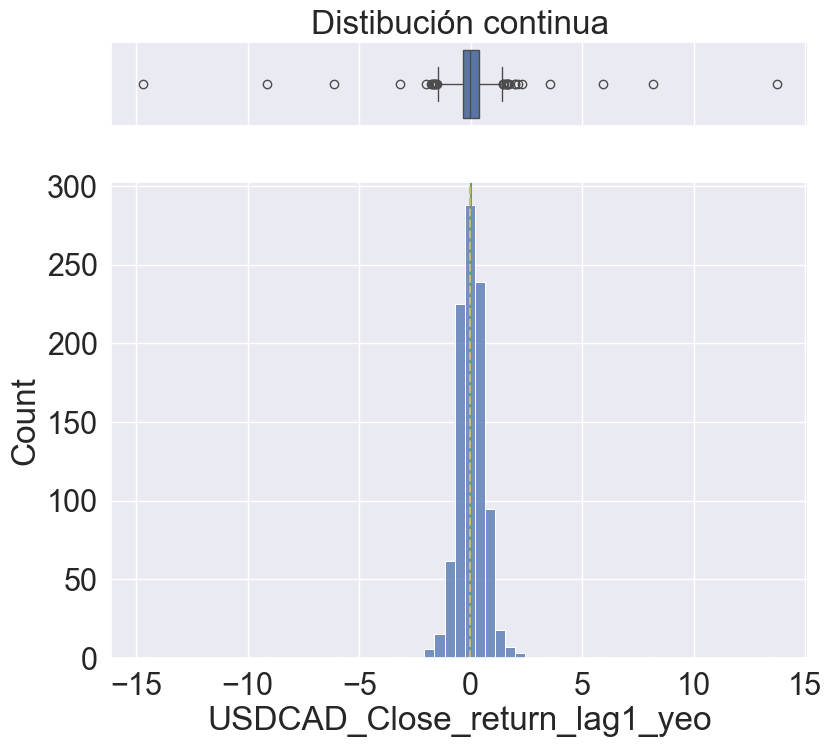

In [6]:
# Visualizar columna
col = 'USDCAD_Close_return_lag1_yeo'
pintar_columna(df_clean[col])

In [7]:
# Tabla de Correlaciones
top_correlaciones(df=df_clean, top_n=30)

,Variable A,Variable B,correlation
363,USDCAD_Close_sma20_pct_diff_sma50_lag1,AUDUSD_Close_sma20_pct_diff_sma50_lag1,0.834000
423,USDCHF_Close_sma20_pct_diff_sma50_lag1,EURUSD_Close_sma20_pct_diff_sma50_lag1,0.785321
1777,GBPUSD_High_pct_diff_Close_lag1_yeo,GBPUSD_Close_return_lag1,0.768430
1612,USDCHF_Close_max20_pct_diff_Close_lag1_log1p,EURUSD_Close_min20_pct_diff_Close_lag1,0.758461
1838,USDJPY_High_pct_diff_Close_lag1_yeo,USDJPY_Close_return_lag1,0.751160
1171,USDCHF_Close_var20_lag1_log,EURUSD_Close_var20_lag1_log,0.750077
2615,USDCHF_Low_pct_diff_Close_lag1_yeo,EURUSD_High_pct_diff_Close_lag1_yeo,0.749648
2341,EURUSD_Low_pct_diff_Close_lag1_yeo,USDCHF_High_pct_diff_Close_lag1_yeo,0.742987
2284,EURUSD_Low_pct_diff_Close_lag1_yeo,EURUSD_Close_return_lag1,0.717256
1717,EURUSD_High_pct_diff_Close_lag1_yeo,EURUSD_Close_return_lag1,0.714140


## Analisis de labels

In [8]:
posibles_labels = [
    'AUDUSD_Close_return',
    'EURUSD_Close_return',
    'GBPUSD_Close_return',
    'USDCAD_Close_return',
    'USDCHF_Close_return',
    'USDJPY_Close_return'
    ]

objetivo = 'EURUSD_Close_return'
objetivo_cat = f"{objetivo}_cat"

df_clean, tabla_bins = categorizar_en_cuantiles(
    df_clean, 
    columna=objetivo, 
    num_cuantiles=3, 
    quitar_original=False
    )

# Se eliminan las posibles labels continuas
df_clean = df_clean.drop(columns=posibles_labels)

print("\n--- Rangos por Categoría ---")
print(tabla_bins)


--- Rangos por Categoría ---
   categoria  lim_inferior  lim_superior
0          1     -0.042661     -0.004675
1          2     -0.004675      0.004651
2          3      0.004651      0.044001


In [9]:
df_clean[objetivo_cat].value_counts()

EURUSD_Close_return_cat
1    322
2    322
3    322
Name: count, dtype: int64

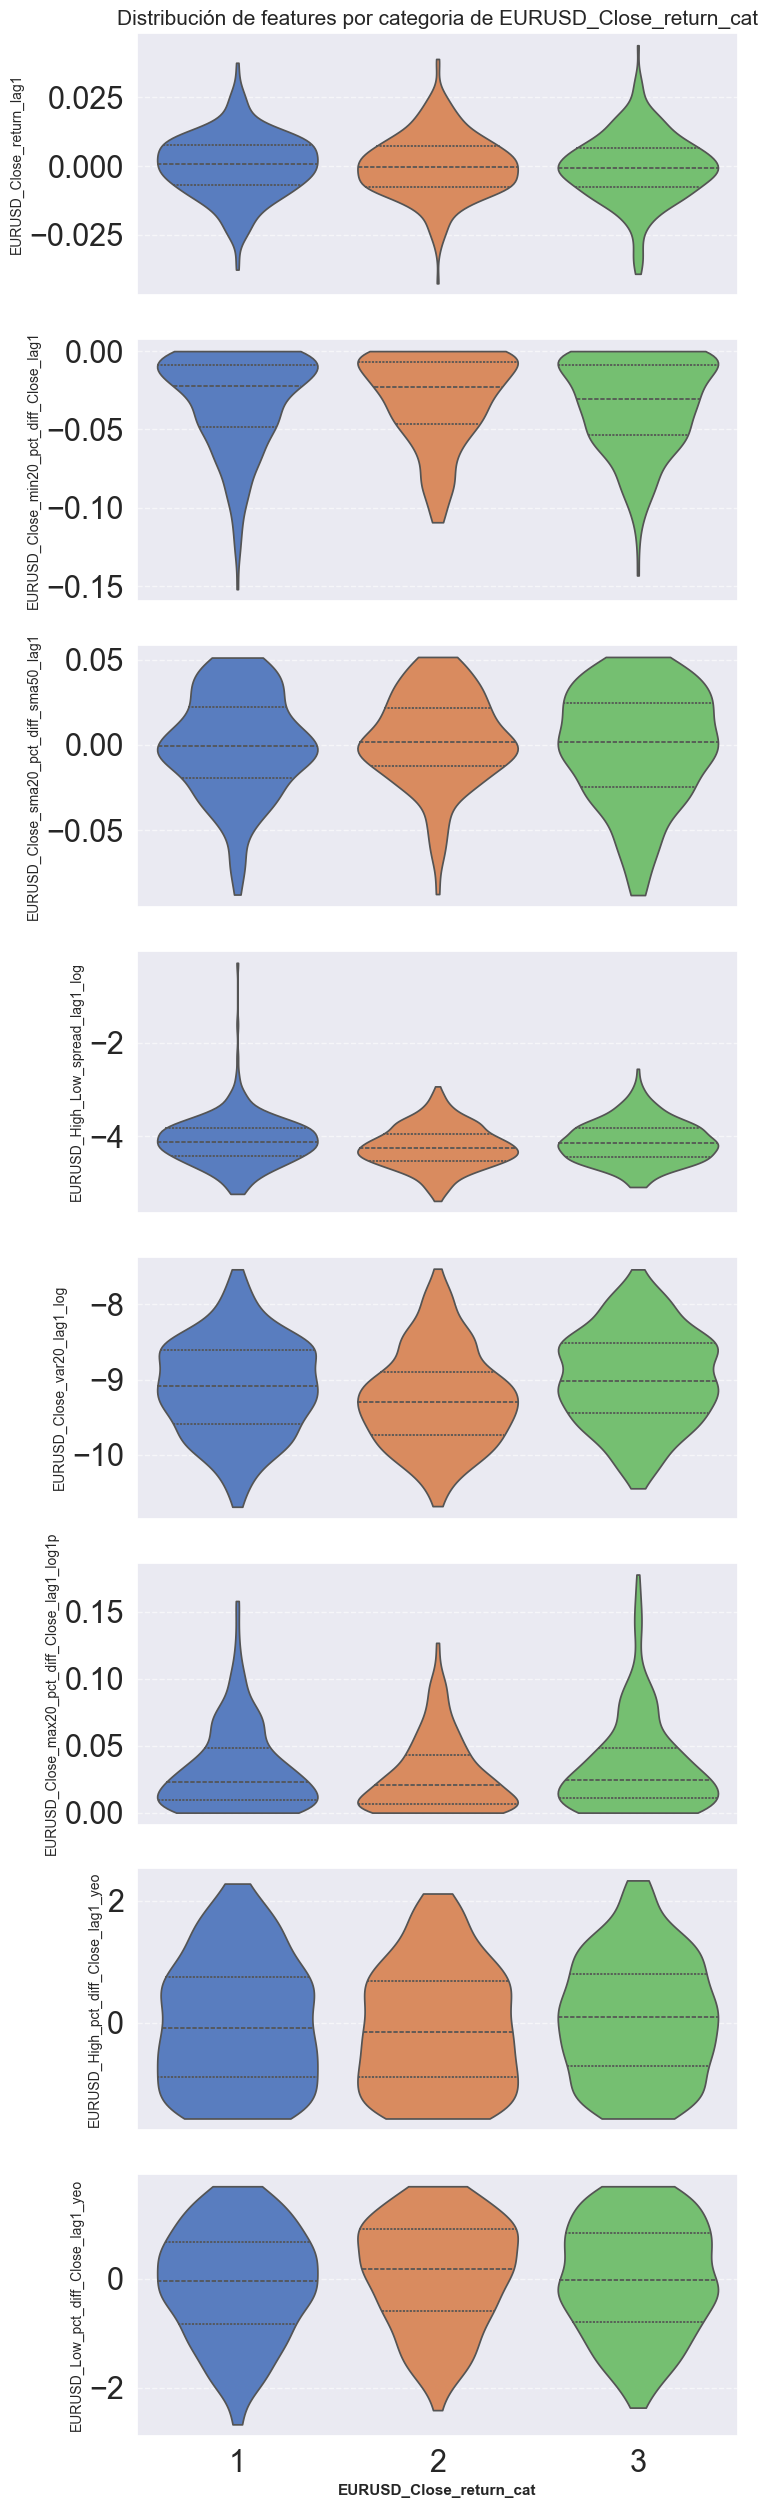

In [13]:
# Violin plot
# Identificar las variables numéricas excluyendo la variable objetivo
target_col = objetivo_cat
numeric_cols = df_clean.select_dtypes(include=["number"]).columns.tolist()

# Asegurar que la columna objetivo no esté en la lista
numeric_cols = [col for col in numeric_cols if col != target_col]

# Filtrar por grupo de variables
cadena = "EURUSD"
columnas = encontrar_columnas(columnas_target=numeric_cols, cadena=cadena)

pintar_violin_plots(
    df=df_clean,
    numeric_cols=columnas,
    target_col=target_col
)